# Model Training — Subset 2 (All Features)


In this notebook we train two regression models — **Random Forest** and **XGBoost** — on **Subset 2**, which contains *all* available features (36 in total). This subset includes both the original 26 features from the dataset and the 10 engineered features we created in the feature engineering step (e.g., `apartmentAge`, `rooms_area`, `floor_elevator`).


In [1]:
import joblib
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV


In [2]:
X_train = pd.read_csv("subsets/train_all.csv")
y_train = pd.read_csv("subsets/train_target.csv")
X_val = pd.read_csv("subsets/val_all.csv")
y_val = pd.read_csv("subsets/val_target.csv")
X_train.head()


,airConditioning,alarm,areaSqm,balcony,bathrooms,closedParkingSpots,elevator,energyClass,fireplace,floor,...,view,yearBuilt,totalParkingSpots,apartmentAge,district,is_renovated,rooms_area,bath_area,floor_elevator,floor_view
0,1,0,3.688879,0,1.0,0.0,1,4,0,6,...,0,1971.0,0.0,55.0,1.0,0,3.688879,3.688879,6,6
1,1,0,4.007333,1,1.0,0.0,1,0,0,6,...,1,2025.0,0.0,1.0,NaN,0,4.007333,4.007333,6,6
2,1,0,4.248495,1,1.0,0.0,1,5,0,7,...,1,1978.0,0.0,48.0,1.0,0,8.496990,4.248495,7,7
3,1,1,4.317488,1,1.0,0.0,0,4,0,4,...,1,1960.0,0.0,66.0,5.0,0,8.634976,4.317488,4,4
4,1,0,3.951244,1,1.0,0.0,1,4,0,7,...,1,1976.0,0.0,50.0,1.0,1,3.951244,3.951244,7,7


---


## Random Forest Regressor


In [3]:
def print_results(results):
    print(f"Best {results.best_score_} using {results.best_params_}\n")
    
    means = results.cv_results_["mean_test_score"]
    stds = results.cv_results_["std_test_score"]
    params = results.cv_results_["params"]
    
    for mean, std, param in zip(means, stds, params):
        print(f"{round(mean,3)} (+/-) {round(2*std,3)} {param}")


In [4]:
rf = RandomForestRegressor()
parameters = {
    "n_estimators": [i for i in range(50, 400, 50)],
    "max_depth": [2, 4, 8, 16, 32, None],
    'min_samples_split': [2, 5],
    'max_features': ['sqrt']
}

rf_cv = RandomizedSearchCV(rf, parameters, scoring='neg_mean_squared_error')
rf_cv.fit(X_train, y_train.values.ravel())

print_results(rf_cv)


Best -0.03040767155684552 using {'n_estimators': 300, 'min_samples_split': 2, 'max_features': 'sqrt', 'max_depth': 16}

-0.034 (+/-) 0.006 {'n_estimators': 100, 'min_samples_split': 5, 'max_features': 'sqrt', 'max_depth': 8}
-0.031 (+/-) 0.006 {'n_estimators': 250, 'min_samples_split': 5, 'max_features': 'sqrt', 'max_depth': 32}
-0.058 (+/-) 0.004 {'n_estimators': 100, 'min_samples_split': 2, 'max_features': 'sqrt', 'max_depth': 2}
-0.034 (+/-) 0.006 {'n_estimators': 50, 'min_samples_split': 5, 'max_features': 'sqrt', 'max_depth': 8}
-0.043 (+/-) 0.006 {'n_estimators': 100, 'min_samples_split': 5, 'max_features': 'sqrt', 'max_depth': 4}
-0.031 (+/-) 0.006 {'n_estimators': 150, 'min_samples_split': 5, 'max_features': 'sqrt', 'max_depth': None}
-0.03 (+/-) 0.006 {'n_estimators': 300, 'min_samples_split': 2, 'max_features': 'sqrt', 'max_depth': 16}
-0.031 (+/-) 0.005 {'n_estimators': 200, 'min_samples_split': 5, 'max_features': 'sqrt', 'max_depth': None}
-0.058 (+/-) 0.005 {'n_estimators'

---


## XGBoost Regressor


In [5]:
xgb = XGBRegressor()
parameters = {
    "n_estimators": [i for i in range(50, 500, 50)],
    "max_depth": [2, 4, 8, 16, 32, None],
    'learning_rate': [0.1, 0.01, 0.001],
    'subsample': [0.5, 0.7, 1]
}

xgb_cv = RandomizedSearchCV(xgb, parameters, scoring='neg_mean_squared_error')
xgb_cv.fit(X_train, y_train.values.ravel())

print_results(xgb_cv)


Best -0.02968047967151242 using {'subsample': 0.5, 'n_estimators': 400, 'max_depth': None, 'learning_rate': 0.01}

-0.095 (+/-) 0.005 {'subsample': 1, 'n_estimators': 100, 'max_depth': 16, 'learning_rate': 0.001}
-0.081 (+/-) 0.004 {'subsample': 1, 'n_estimators': 250, 'max_depth': 16, 'learning_rate': 0.001}
-0.064 (+/-) 0.003 {'subsample': 0.5, 'n_estimators': 50, 'max_depth': None, 'learning_rate': 0.01}
-0.03 (+/-) 0.004 {'subsample': 1, 'n_estimators': 450, 'max_depth': 2, 'learning_rate': 0.1}
-0.09 (+/-) 0.004 {'subsample': 0.5, 'n_estimators': 150, 'max_depth': 8, 'learning_rate': 0.001}
-0.03 (+/-) 0.006 {'subsample': 0.5, 'n_estimators': 400, 'max_depth': None, 'learning_rate': 0.01}
-0.038 (+/-) 0.005 {'subsample': 1, 'n_estimators': 150, 'max_depth': None, 'learning_rate': 0.01}
-0.039 (+/-) 0.006 {'subsample': 1, 'n_estimators': 400, 'max_depth': 32, 'learning_rate': 0.01}
-0.038 (+/-) 0.007 {'subsample': 1, 'n_estimators': 200, 'max_depth': 16, 'learning_rate': 0.1}
-0.07

---


## Feature Importance Comparison


In [6]:
# Random Forest feature importance
rf_feat_imp = rf_cv.best_estimator_.feature_importances_
rf_imp_dict = {"Feature RF" : list(X_train.columns),
        "Feature Importance RF" : rf_feat_imp}
rf_importance = pd.DataFrame(rf_imp_dict)
rf_sorting_features = rf_importance.sort_values(by=["Feature Importance RF"], ascending=False)

# XGBoost feature importance
xgb_feat_imp = xgb_cv.best_estimator_.feature_importances_
xgb_imp_dict = {"Feature XGB" : list(X_train.columns),
        "Feature Importance XGB" : xgb_feat_imp}
xgb_importance = pd.DataFrame(xgb_imp_dict)
xgb_sorting_features = xgb_importance.sort_values(by=["Feature Importance XGB"], ascending=False)

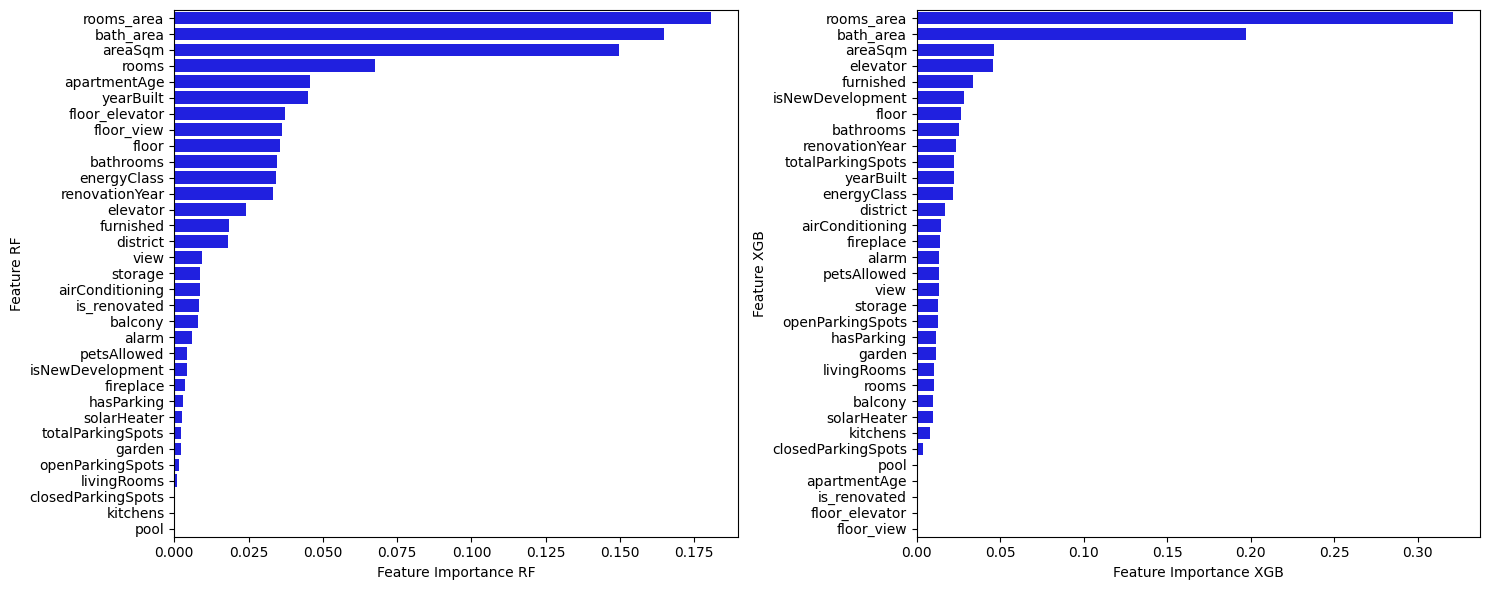

In [7]:
# plotting feature importance graph
fig,ax = plt.subplots(1,2, figsize=(15,6))
bar = sns.barplot(x='Feature Importance RF', y='Feature RF', data=rf_sorting_features, color='blue', ax=ax[0])
bar = sns.barplot(x='Feature Importance XGB', y='Feature XGB', data=xgb_sorting_features, color='blue', ax=ax[1])

plt.tight_layout()
plt.show()


---


## Saving the Trained Models


In [8]:
# Save models
joblib.dump(rf_cv.best_estimator_, "models/model_rf_all.pkl")
joblib.dump(xgb_cv.best_estimator_, "models/model_xgb_all.pkl")


['models/model_xgb_all.pkl']